# Does turnover change over the course of a month?

**Purpose.** Many people are paid at the end or the start of the month. The idea: shortly before payday money is tight, so people buy less, especially "treats" such as croissants (group 3). This notebook checks whether turnover is **lower at the end of the month** than at the start, for the whole branch and per product group.

This is an exploration, not a model.

> **Summary**
> - **No sign that people spend less at the end of the month.** The bins differ by only a few percent, and the error bars overlap. The last bin (26-31) is even slightly *higher* than the others (total +1.7 % vs. days 1-5).
> - **Croissants are not hit harder.** They are also slightly higher at the end of the month (+3.4 %). Only confectionery is a little lower (−3.3 %).
> - **The small end-of-month bump could be Christmas week.** It likely comes from the days between Christmas and New Year (27–30 Dec), which are not in our event calendar. Without December, days 1-5 and 26-31 are almost the same.
> - **For the forecast:** the day of the month might not be worth a feature. Weekday, season and holidays matter far more.

**Method (kept simple).**
1. Remove all public holidays, special days (Christmas Eve, New Year's Eve, Easter/Whit Sunday) and Kiel Week, because they always fall on the same days of the month and would distort the comparison. Football and handball match days stay in.
2. Put each day into a **5-day bin** by its day of the month (1–5, 6–10, …, 26–31).
3. Report the **mean turnover** per bin.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

BASE_URL = "https://raw.githubusercontent.com/opencampus-sh/intro-to-data-science-and-ml/main/data/bakery/"
GROUPS = {1: "Bread", 2: "Rolls", 3: "Croissant", 4: "Confectionery", 5: "Cake", 6: "Seasonal bread"}
ORDER = ["Bread", "Rolls", "Croissant", "Confectionery", "Cake"]
WEEKDAYS = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

sales = pd.read_csv(BASE_URL + "umsatzdaten_gekuerzt.csv", parse_dates=["Datum"])
sales["group"] = sales["Warengruppe"].map(GROUPS)
events = pd.read_csv("../0_DataPreparation/events.csv", parse_dates=["Datum"])
sales.head()

,id,Datum,Warengruppe,Umsatz,group
0,1307011,2013-07-01,1,148.828353,Bread
1,1307021,2013-07-02,1,159.793757,Bread
2,1307031,2013-07-03,1,111.885594,Bread
3,1307041,2013-07-04,1,168.864941,Bread
4,1307051,2013-07-05,1,171.280754,Bread


## Step 1 – Remove holidays and special days

From our event calendar (`0_DataPreparation/events.csv`) we drop every day with a tag **except** `match_holstein` and `match_thw`. That removes public holidays (`holiday_*`), special days (`special_*`) and Kiel Week (`kiwo`).

Group 6 (seasonal bread) is left out: it is only sold in a few months of the year, so there is too little data per bin.

In [2]:
remove_days = events.loc[~events["tag"].str.startswith("match_"), "Datum"].unique()

before = len(sales)
df = sales[~sales["Datum"].isin(remove_days) & (sales["Warengruppe"] != 6)].copy()
print("rows before:", before, "| rows after:", len(df))
print("removed days that were in the sales data:", sales.loc[sales["Datum"].isin(remove_days), "Datum"].nunique())

rows before: 9334 | rows after: 8624
removed days that were in the sales data: 85


## Step 2 – 5-day bins

Day 1–5 → bin "1-5", …, days 26–31 → bin "26-31" (the last bin has up to 6 days).

**Quick check:** the weekday mix should be about the same in every bin, otherwise a bin with more Saturdays would look busier just because of the weekday. The table counts how many days of each weekday fall into each bin.

In [3]:
BINS = ["1-5", "6-10", "11-15", "16-20", "21-25", "26-31"]
df["day"] = df["Datum"].dt.day
df["bin"] = pd.cut(df["day"], bins=[0, 5, 10, 15, 20, 25, 31], labels=BINS)

days = df.drop_duplicates("Datum").copy()
days["weekday"] = pd.Categorical(days["Datum"].dt.day_name(), categories=WEEKDAYS, ordered=True)
pd.crosstab(days["bin"], days["weekday"])

weekday,Monday,Tuesday,Wednesday,Thursday,Friday,Saturday,Sunday
bin,,,,,,,
1-5,39,41,42,41,39,40,38
6-10,41,45,43,40,44,44,43
11-15,42,42,44,43,43,43,43
16-20,38,42,43,43,44,38,35
21-25,37,39,39,35,37,39,37
26-31,46,45,45,44,43,44,41


## Step 3 – Whole branch

Total turnover per day (sum of the five groups), then the mean per bin. The error bars are 95 % confidence intervals: if they overlap a lot, the difference between bins may well be chance.

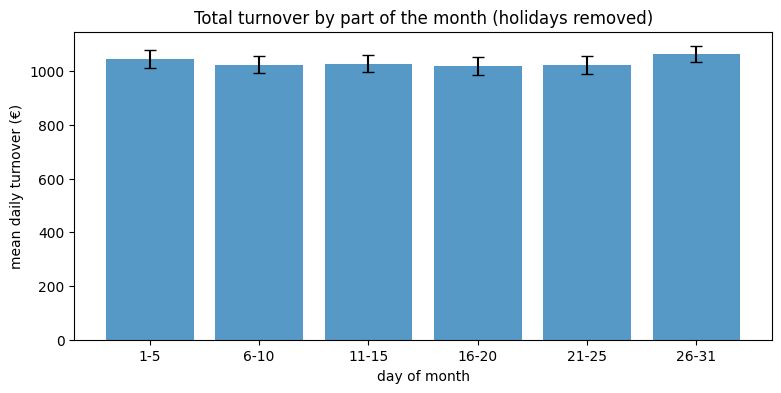

,mean,sem,count,vs_all_days_%
bin,,,,
1-5,1044.3,17.3,280,1.0
6-10,1024.2,15.7,300,-0.9
11-15,1027.1,16.3,300,-0.6
16-20,1020.0,16.9,283,-1.3
21-25,1021.5,17.5,263,-1.2
26-31,1062.2,15.1,308,2.8


In [4]:
total = df.groupby(["Datum", "bin"], observed=True, as_index=False)["Umsatz"].sum()
t = total.groupby("bin", observed=True)["Umsatz"].agg(["mean", "sem", "count"])

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(t.index.astype(str), t["mean"], yerr=1.96 * t["sem"], color="tab:blue", alpha=0.75, capsize=4)
ax.set_xlabel("day of month")
ax.set_ylabel("mean daily turnover (€)")
ax.set_title("Total turnover by part of the month (holidays removed)")
plt.show()

t["vs_all_days_%"] = (t["mean"] / total["Umsatz"].mean() - 1) * 100
t.round(1)

## Step 4 – Per product group

Same as above, but for each group. The table shows how much each bin is above (+) or below (−) the group's average day, in %. If the payday idea is right, the last bin (26-31) should be negative, most clearly for croissants.

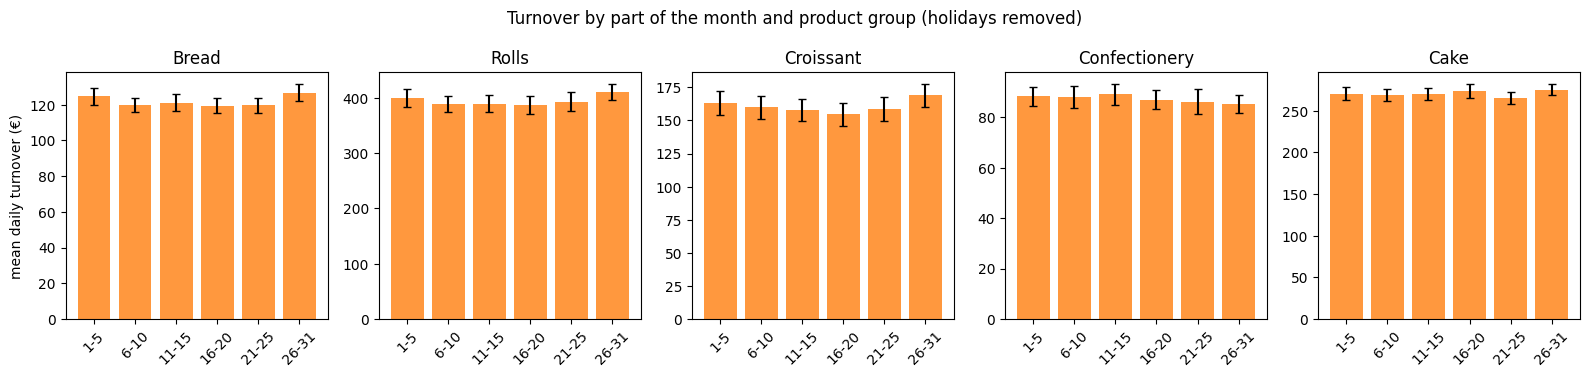

bin,1-5,6-10,11-15,16-20,21-25,26-31
group,,,,,,
Bread,2.2,-1.9,-0.7,-2.0,-2.0,4.0
Rolls,1.2,-1.5,-1.4,-2.0,-0.4,3.8
Croissant,1.6,-0.5,-1.7,-3.7,-1.1,5.1
Confectionery,1.1,0.8,2.0,-0.3,-1.4,-2.3
Cake,-0.1,-0.7,-0.2,1.0,-1.9,1.7


In [5]:
g = df.groupby(["group", "bin"], observed=True)["Umsatz"].agg(["mean", "sem"]).reset_index()

fig, axes = plt.subplots(1, len(ORDER), figsize=(16, 3.8))
for ax, name in zip(axes, ORDER):
    s = g[g["group"] == name]
    ax.bar(s["bin"].astype(str), s["mean"], yerr=1.96 * s["sem"], color="tab:orange", alpha=0.8, capsize=3)
    ax.set_title(name)
    ax.tick_params(axis="x", rotation=45)
axes[0].set_ylabel("mean daily turnover (€)")
fig.suptitle("Turnover by part of the month and product group (holidays removed)")
plt.tight_layout()
plt.show()

group_mean = df.groupby("group")["Umsatz"].mean()
pct = g.pivot(index="group", columns="bin", values="mean").loc[ORDER]
pct = (pct.div(group_mean.loc[ORDER], axis=0) - 1) * 100
pct.round(1)